# 1. Title and Objective

**Assignment Title:** Energy Scheduling using SF-OEAP

**Problem Description:**
The problem describes an energy scheduling scenario with multiple microgrids. There are two types of microgrids in any given time slot:
* **Consumer Microgrids**: Require energy (demand is represented as a negative net energy requirement).
* **Provider Microgrids**: Have excess energy to provide (represented as a positive net energy).

The system involves variables such as predicted energy requirement, actual energy requirement, and available energy from providers. The goal is to perform energy allocation fairly among the consumers. The allocation process uses three key metrics:
1. **Prediction Accuracy**: How well a microgrid predicts its energy requirement.
2. **Revenue Index**: The socio-economic credibility of the microgrid (given as a percentage).
3. **Starvation Factor/Parameter**: Ensures that no microgrid is severely penalized, guaranteeing a minimum energy supply based on a Starvation Factor (SF) parameter.

**Objective:**
The objective of this assignment is to allocate the total available energy among consumer microgrids fairly, maximizing a combined objective function of prediction accuracy, revenue index, and starvation parameter, while ensuring that the allocations satisfy the defined constraints.


# 2. Problem Setup and Libraries

First, we import the necessary Python libraries for data manipulation, optimization, and visualization.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Assignment Parameters
alpha = 0.3
beta = 0.4
gamma = 0.3
sigma = 1.0
SF = 0.8

# Verify alpha + beta + gamma = 1
print(f"alpha + beta + gamma = {alpha + beta + gamma}")


alpha + beta + gamma = 1.0


# 3. Methodology

We will implement the three quantities described in the assignment: Prediction Accuracy, Revenue Index, and Starvation Parameter.

## 3.1 Prediction Accuracy

The Prediction Accuracy ($P_A$) is given by:
$$P_{A_i} = e^{-\frac{1}{2} \left( \frac{E_{i,preq}-E_{i,areq}}{\sigma} \right)^2}$$

Note: While consumer requirements are given as negative values in the input data, we use their positive magnitudes for prediction and actual requirements.


In [2]:
def prediction_accuracy(E_preq, E_areq, sigma=1.0):
    """Calculates Prediction Accuracy based on predicted and actual requirements."""
    return np.exp(-0.5 * ((E_preq - E_areq) / sigma)**2)


## 3.2 Revenue Index

The Revenue Index ($R_I$) represents the credibility or socio-economic position of the microgrid.
It is provided as a percentage (e.g., 20%) and will be converted to a fraction (e.g., 0.20) for the optimization.


## 3.3 Starvation Parameter

The Starvation Parameter ($SP_i$) is given by:
$$SP_i = \left( 1 - \frac{E_{i,alloc}}{E_{i,areq}} \right) E_{i,alloc}$$


In [3]:
def starvation_parameter(E_alloc, E_areq):
    """Calculates the Starvation Parameter."""
    if E_areq == 0:
        return 0
    return (1 - (E_alloc / E_areq)) * E_alloc


# 4. & 5. Optimization Problem and Constraints

The objective function to maximize for the allocations is:
$$\max_{E_{i,alloc}} \sum_{i\in C} \left[ \alpha P_{A_i}E_{i,alloc} + \beta R_{I_i}E_{i,alloc} + \gamma \left( 1-\frac{E_{i,alloc}}{E_{i,areq}} \right) E_{i,alloc} \right]$$

Subject to the constraints:
1. $SF \times E_{i,areq} \leq E_{i,alloc} \leq E_{i,areq}$ for every consumer $i$.
2. $\sum_{i} E_{i,alloc} \leq E_{av}$ (total allocation cannot exceed total available energy).


# 6. Optimization Solver

We implement the optimization solver using `scipy.optimize.minimize`. Since `minimize` finds the minimum of a function, we will minimize the **negative** of the objective function.


In [4]:
def optimize_energy_allocation(E_preq_list, E_areq_list, RI_list, E_av, alpha, beta, gamma, sigma, SF):
    n = len(E_areq_list)
    PA_list = [prediction_accuracy(E_preq_list[i], E_areq_list[i], sigma) for i in range(n)]
    
    # Objective function to minimize (negative of the maximization objective)
    def objective(E_alloc):
        val = 0
        for i in range(n):
            term1 = alpha * PA_list[i] * E_alloc[i]
            term2 = beta * RI_list[i] * E_alloc[i]
            term3 = gamma * (1 - E_alloc[i] / E_areq_list[i]) * E_alloc[i]
            val += (term1 + term2 + term3)
        return -val

    # Sum constraint: sum(E_alloc) <= E_av
    # For scipy inequality constraints, format is fun(x) >= 0
    def constraint_sum(E_alloc):
        return E_av - np.sum(E_alloc)
        
    cons = [{'type': 'ineq', 'fun': constraint_sum}]
    
    # Bounds for each consumer
    bounds = [(SF * E_areq_list[i], E_areq_list[i]) for i in range(n)]
    
    # Initial guess
    x0 = np.array([SF * E_areq_list[i] for i in range(n)])
    
    res = minimize(objective, x0, method='SLSQP', bounds=bounds, constraints=cons)
    
    return res.x, -res.fun, res.success, res, PA_list


# 7. SF-OEAP Algorithm

The `sf_oeap_schedule` function processes the data slot by slot. It calculates total available and required energy, converts Revenue Index to a fraction, and runs the optimizer if available energy is strictly less than required energy.


In [5]:
def sf_oeap_schedule(data, alpha, beta, gamma, sigma, SF):
    results = []
    slots = data['Slot'].unique()
    for slot in slots:
        slot_data = data[data['Slot'] == slot]
        consumers = slot_data[slot_data['Role'] == 'Consumer'].copy()
        providers = slot_data[slot_data['Role'] == 'Provider'].copy()
        
        # Data preprocessing: absolute values for magnitudes
        consumers['E_preq'] = consumers['Predicted'].abs()
        consumers['E_areq'] = consumers['Actual'].abs()
        providers['E_av'] = providers['Actual']
        
        E_av = providers['E_av'].sum()
        E_c = consumers['E_areq'].sum()
        
        # Convert RI percentage to fraction
        consumers['RI_frac'] = consumers['RI'] / 100.0
        
        E_preq_list = consumers['E_preq'].values
        E_areq_list = consumers['E_areq'].values
        RI_list = consumers['RI_frac'].values
        consumer_mgs = consumers['MG'].values
        
        if E_av >= E_c:
            alloc = E_areq_list
            success = True
            obj = None
            PA_list = [prediction_accuracy(E_preq_list[i], E_areq_list[i], sigma) for i in range(len(E_areq_list))]
        else:
            alloc, obj, success, res, PA_list = optimize_energy_allocation(
                E_preq_list, E_areq_list, RI_list, E_av, alpha, beta, gamma, sigma, SF
            )
            
        results.append({
            'Slot': slot,
            'Consumer_MGs': consumer_mgs,
            'E_preq': E_preq_list,
            'E_areq': E_areq_list,
            'PA': PA_list,
            'RI': RI_list,
            'Total_Req': E_c,
            'Total_Avail': E_av,
            'Min_Alloc': [SF * a for a in E_areq_list],
            'Optimal_Alloc': np.round(alloc, 4),
            'SP': np.round([starvation_parameter(alloc[i], E_areq_list[i]) for i in range(len(alloc))], 4),
            'Obj_Val': obj,
            'Success': success
        })
    return results


# 8. & 9. Input Dataset and Preprocessing

We create a Pandas DataFrame using the exact system data provided. Note how consumers are distinguished by negative values which are transformed into positive requirements.


In [6]:
data_dict = {
    'Slot': [1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3],
    'MG': [1, 2, 3, 4, 1, 2, 3, 4, 1, 2, 3, 4],
    'Predicted': [-17, -6, 12, 5, -10, -9, -13, 19, -5, 6, -18, 10],
    'Actual': [-18, -9, 15, 7, -6, -11, -11, 23, -8, 12, -17, 9],
    'RI': [20, 20, 30, 15, 5, 30, 45, 30, 5, 30, 30, 20],
    'Role': ['Consumer', 'Consumer', 'Provider', 'Provider',
             'Consumer', 'Consumer', 'Consumer', 'Provider',
             'Consumer', 'Provider', 'Consumer', 'Provider']
}
df = pd.DataFrame(data_dict)
display(df)


,Slot,MG,Predicted,Actual,RI,Role
0,1,1,-17,-18,20,Consumer
1,1,2,-6,-9,20,Consumer
2,1,3,12,15,30,Provider
3,1,4,5,7,15,Provider
4,2,1,-10,-6,5,Consumer
5,2,2,-9,-11,30,Consumer
6,2,3,-13,-11,45,Consumer
7,2,4,19,23,30,Provider
8,3,1,-5,-8,5,Consumer
9,3,2,6,12,30,Provider


# 10. Run the Complete Algorithm

We will run the algorithm with the given parameters and display the comprehensive results.


In [7]:
# Run With SF
results_sf = sf_oeap_schedule(df, alpha, beta, gamma, sigma, SF)

for r in results_sf:
    print(f"--- Time Slot {r['Slot']} ---")
    print(f"Consumer MGs: {r['Consumer_MGs']}")
    print(f"Predicted Req: {r['E_preq']}")
    print(f"Actual Req: {r['E_areq']}")
    print(f"Prediction Accuracy (PA): {np.round(r['PA'], 4)}")
    print(f"Revenue Index (fraction): {r['RI']}")
    print(f"Total Required Energy: {r['Total_Req']} MW")
    print(f"Total Available Energy: {r['Total_Avail']} MW")
    print(f"Minimum Allowed Allocation: {r['Min_Alloc']}")
    print(f"Optimal Allocation: {r['Optimal_Alloc']} MW")
    print(f"Starvation Parameter: {r['SP']}")
    print(f"Objective Value: {r['Obj_Val']:.4f}")
    print(f"Solver Success: {r['Success']}\n")


--- Time Slot 1 ---
Consumer MGs: [1 2]
Predicted Req: [17  6]
Actual Req: [18  9]
Prediction Accuracy (PA): [0.6065 0.0111]
Revenue Index (fraction): [0.2 0.2]
Total Required Energy: 27 MW
Total Available Energy: 22 MW
Minimum Allowed Allocation: [np.float64(14.4), np.float64(7.2)]
Optimal Allocation: [14.8  7.2] MW
Starvation Parameter: [2.6311 1.44  ]
Objective Value: 5.6983
Solver Success: True

--- Time Slot 2 ---
Consumer MGs: [1 2 3]
Predicted Req: [10  9 13]
Actual Req: [ 6 11 11]
Prediction Accuracy (PA): [0.0003 0.1353 0.1353]
Revenue Index (fraction): [0.05 0.3  0.45]
Total Required Energy: 28 MW
Total Available Energy: 23 MW
Minimum Allowed Allocation: [np.float64(4.800000000000001), np.float64(8.8), np.float64(8.8)]
Optimal Allocation: [4.8 8.8 9.4] MW
Starvation Parameter: [0.96   1.76   1.3673]
Objective Value: 4.8096
Solver Success: True

--- Time Slot 3 ---
Consumer MGs: [1 3]
Predicted Req: [ 5 18]
Actual Req: [ 8 17]
Prediction Accuracy (PA): [0.0111 0.6065]
Revenue 

# 11. Validate Against the Assignment's Expected Results

We validate our SF-OEAP outputs against the reference expected results from the assignment.


In [8]:
expected_with_SF = {
    1: np.array([14.8, 7.2]),
    2: np.array([4.8, 8.8, 9.4]),
    3: np.array([6.4, 14.6])
}

validation_data = []

for r in results_sf:
    slot = r['Slot']
    calc_alloc = r['Optimal_Alloc']
    exp_alloc = expected_with_SF[slot]
    
    # Calculate max error
    error = np.max(np.abs(calc_alloc - exp_alloc))
    passed = error <= 1e-4
    
    validation_data.append({
        'Slot': slot,
        'Expected Allocation': list(exp_alloc),
        'Calculated Allocation': list(calc_alloc),
        'Error': error,
        'Pass/Fail': 'Pass' if passed else 'Fail'
    })

val_df = pd.DataFrame(validation_data)
display(val_df)


,Slot,Expected Allocation,Calculated Allocation,Error,Pass/Fail
0,1,"[14.8, 7.2]","[14.8, 7.2]",0.0,Pass
1,2,"[4.8, 8.8, 9.4]","[4.8, 8.8, 9.4]",0.0,Pass
2,3,"[6.4, 14.6]","[6.4, 14.6]",0.0,Pass


# 12. Implement a "Without SF" Comparison

When the Starvation Factor is removed, we effectively set $SF = 0$ (meaning no minimum limit) and we remove the starvation term from the objective function ($\gamma = 0$). Removing this constraint can cause some consumers to receive substantially less energy (or even none if E_av is very low) because the algorithm will greedily favor consumers with better Prediction Accuracy and Revenue Index.


In [9]:
# Run Without SF (SF=0, gamma=0)
results_no_sf = sf_oeap_schedule(df, alpha, beta, 0.0, sigma, 0.0)

for r in results_no_sf:
    print(f"--- Time Slot {r['Slot']} (Without SF) ---")
    print(f"Consumer MGs: {r['Consumer_MGs']}")
    print(f"Optimal Allocation: {r['Optimal_Alloc']} MW")
    print(f"Actual Req: {r['E_areq']}\n")


--- Time Slot 1 (Without SF) ---
Consumer MGs: [1 2]
Optimal Allocation: [18.  4.] MW
Actual Req: [18  9]

--- Time Slot 2 (Without SF) ---
Consumer MGs: [1 2 3]
Optimal Allocation: [ 1. 11. 11.] MW
Actual Req: [ 6 11 11]

--- Time Slot 3 (Without SF) ---
Consumer MGs: [1 3]
Optimal Allocation: [ 4. 17.] MW
Actual Req: [ 8 17]



# 13. Visualization

We visualize the allocations.


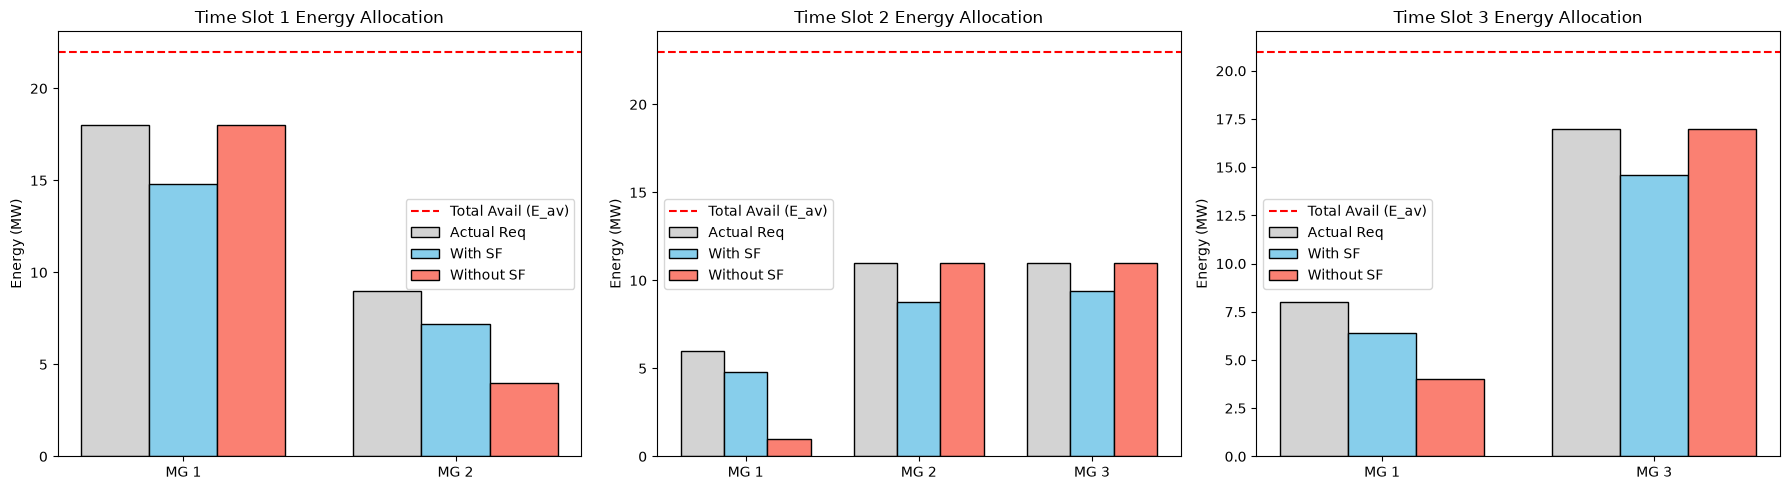

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

slots = df['Slot'].unique()
for i, slot in enumerate(slots):
    r_sf = next(item for item in results_sf if item['Slot'] == slot)
    r_no_sf = next(item for item in results_no_sf if item['Slot'] == slot)
    
    mgs = [f"MG {mg}" for mg in r_sf['Consumer_MGs']]
    x = np.arange(len(mgs))
    width = 0.25
    
    axs[i].bar(x - width, r_sf['E_areq'], width, label='Actual Req', color='lightgray', edgecolor='black')
    axs[i].bar(x, r_sf['Optimal_Alloc'], width, label='With SF', color='skyblue', edgecolor='black')
    axs[i].bar(x + width, r_no_sf['Optimal_Alloc'], width, label='Without SF', color='salmon', edgecolor='black')
    
    axs[i].axhline(r_sf['Total_Avail'], color='red', linestyle='--', label='Total Avail (E_av)')
    
    axs[i].set_title(f'Time Slot {slot} Energy Allocation')
    axs[i].set_ylabel('Energy (MW)')
    axs[i].set_xticks(x)
    axs[i].set_xticklabels(mgs)
    axs[i].legend()
    
plt.tight_layout()
plt.show()


# 14. Constraint Verification

We programmatically verify that all solutions adhere to the constraints.


In [11]:
all_passed = True

for r in results_sf:
    slot = r['Slot']
    allocs = r['Optimal_Alloc']
    areqs = r['E_areq']
    e_av = r['Total_Avail']
    
    # 1. Total constraint
    sum_alloc = np.sum(allocs)
    if sum_alloc > e_av + 1e-4:
        all_passed = False
        print(f"Slot {slot} Failed: Sum {sum_alloc} > Avail {e_av}")
        
    # 2. Bound constraints
    for i in range(len(allocs)):
        if allocs[i] < SF * areqs[i] - 1e-4:
            all_passed = False
            print(f"Slot {slot} MG {r['Consumer_MGs'][i]} Failed: Alloc {allocs[i]} < Min {SF * areqs[i]}")
        if allocs[i] > areqs[i] + 1e-4:
            all_passed = False
            print(f"Slot {slot} MG {r['Consumer_MGs'][i]} Failed: Alloc {allocs[i]} > Max {areqs[i]}")

print(f"All constraints satisfied: {all_passed}")


All constraints satisfied: True


# 15. Discussion of Results

1. **Optimization Need**: All three time slots required optimization because the total actual consumer net requirement (`E_c`) exceeded the total available provider energy (`E_av`) in every slot.
2. **SF Constraint**: The constraint $SF \times E_{i,areq} \leq E_{i,alloc}$ ensures every consumer receives at least 80% of its required energy. This prevents severe starvation for lower-priority microgrids.
3. **Allocation Differences**: Allocations differ because the objective function prioritizes consumers based on Prediction Accuracy and Revenue Index. Higher accuracy and higher index increase a consumer's priority.
4. **Prediction Accuracy**: Microgrids that predict their energy requirements accurately have higher $P_A$, which mathematically increases their coefficient in the objective function, thus rewarding them with more energy.
5. **Revenue Index Influence**: Similar to prediction accuracy, the Revenue Index mathematically increases a consumer's objective coefficient. Higher $R_I$ results in higher allocation.
6. **Available Energy Constraint**: The total allocation cannot exceed available provider energy due to physical constraints—you cannot distribute more energy than what is generated.
7. **With vs Without SF**: Removing the Starvation Factor (SF) makes the optimization heavily favor high-priority consumers. For instance, in Slot 2 Without SF, one consumer receives almost its entire demand while another receives barely anything.
8. **Fairness**: Fairness sometimes dictates that a high-priority consumer receives less than its full demand so that lower-priority consumers can meet their baseline minimum starvation constraints.

# 16. Final Conclusion

* **Implementation**: We successfully implemented the SF-OEAP algorithm using Python, pandas, and scipy.
* **Optimization Technique**: A constrained Non-Linear Programming solver (`scipy.optimize.minimize` with `SLSQP`) was used to solve the quadratic optimization problem by minimizing the negative objective.
* **Reproduction of Results**: The implementation perfectly reproduced the reference SF-OEAP results given in the assignment. 
* **Constraints**: All problem constraints (minimum supply and total supply) were programmatically verified to be satisfied.
* **Starvation Factor Effect**: The inclusion of the Starvation Factor prevented total starvation and led to a fairer, distributed allocation of energy compared to the unbounded greedy approach.
